In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pickle
from som_rl.som.som_backend import SharpZBackendConfig, SharpZSOMBackend

DATA = "data"
H, W = 200, 200
K = 11

In [2]:
npz = np.load(f"{DATA}/correlations_dl/npairs_compact.npz")
dd, dr, rd, rr = npz["dd"], npz["dr"], npz["rd"], npz["rr"]

node_indices_photo = np.load(f"{DATA}/node_indices_fc.npy")
initial_node_bins  = np.load(f"{DATA}/nodes_labels_initial_fc_200_ext.npy").astype(np.int32)
reference_labels   = np.load(f"{DATA}/reference_labels_fc_fc.npy").astype(np.int32)

weighted_clusters  = np.load(f"{DATA}/weighted_clusters_5c_1t200.npy")  # (L,N)
print("weighted_clusters:", weighted_clusters.shape, weighted_clusters.dtype)


weighted_clusters: (201, 40000) int64


In [3]:
P_SOM_PKL = os.path.join(DATA, "som_200_5colours_rand.pkl")

with open(P_SOM_PKL, "rb") as f:
    som_obj = pickle.load(f)

# Cell 5 — helper to *find* a plausible U-matrix / distance map inside the object
def find_umatrix_candidate(obj, H=200, W=200):
    """
    Tries common SOM libraries/fields:
      - MiniSom: distance_map()
      - somoclu: umatrix, get_umatrix()
      - generic: attributes containing 'u', 'umatrix', 'distance', 'dist', 'umat'
    Returns (name, array) or (None, None).
    """
    # common methods
    for meth in ["distance_map", "umatrix", "get_umatrix", "getUmatrix", "get_u_matrix"]:
        if hasattr(obj, meth) and callable(getattr(obj, meth)):
            try:
                out = getattr(obj, meth)()
                arr = np.asarray(out)
                if arr.size == H * W or arr.shape == (H, W):
                    return f"method:{meth}", arr.reshape(H, W) if arr.size == H * W else arr
            except Exception:
                pass

    # common attributes
    candidates = []
    for name in dir(obj):
        if name.startswith("_"):
            continue
        lname = name.lower()
        if any(k in lname for k in ["umatrix", "u_matrix", "distance", "distmap", "dist_map", "umat"]):
            try:
                val = getattr(obj, name)
                if callable(val):
                    continue
                arr = np.asarray(val)
                if arr.size == H * W or arr.shape == (H, W):
                    candidates.append((name, arr.reshape(H, W) if arr.size == H * W else arr))
            except Exception:
                pass

    if candidates:
        # pick the first; you can inspect others if needed
        return f"attr:{candidates[0][0]}", candidates[0][1]

    # dict case
    if isinstance(obj, dict):
        for k, v in obj.items():
            lk = str(k).lower()
            if any(s in lk for s in ["umatrix", "u_matrix", "distance", "dist", "umat"]):
                try:
                    arr = np.asarray(v)
                    if arr.size == H * W or arr.shape == (H, W):
                        return f"dict:{k}", arr.reshape(H, W) if arr.size == H * W else arr
                except Exception:
                    pass

    return None, None

name, umatrix = find_umatrix_candidate(som_obj, H=200, W=200)
print("U-matrix candidate:", name)
print("U-matrix found:", umatrix is not None)
if umatrix is not None:
    print("  shape:", umatrix.shape, "dtype:", umatrix.dtype, "min/max:", float(np.nanmin(umatrix)), float(np.nanmax(umatrix)))


U-matrix candidate: attr:umatrix
U-matrix found: True
  shape: (200, 200) dtype: float32 min/max: 0.013760206289589405 0.8203610181808472


In [4]:
cfg = SharpZBackendConfig(grid_shape=(H,W), num_bins=K)

som = SharpZSOMBackend(
    cfg=cfg,
    dd=dd, dr=dr, rd=rd, rr=rr,
    node_indices_photo=node_indices_photo,
    initial_node_bins=initial_node_bins,
    reference_labels=reference_labels,
    umatrix=umatrix,
    weighted_clusters=weighted_clusters,
)

print("trace:", som.trace_xi())
print("energy:", som.energy_E())
print("levels:", som.levels_available())


trace: 0.2785188710136125
energy: 0.023775093565945846
levels: 201


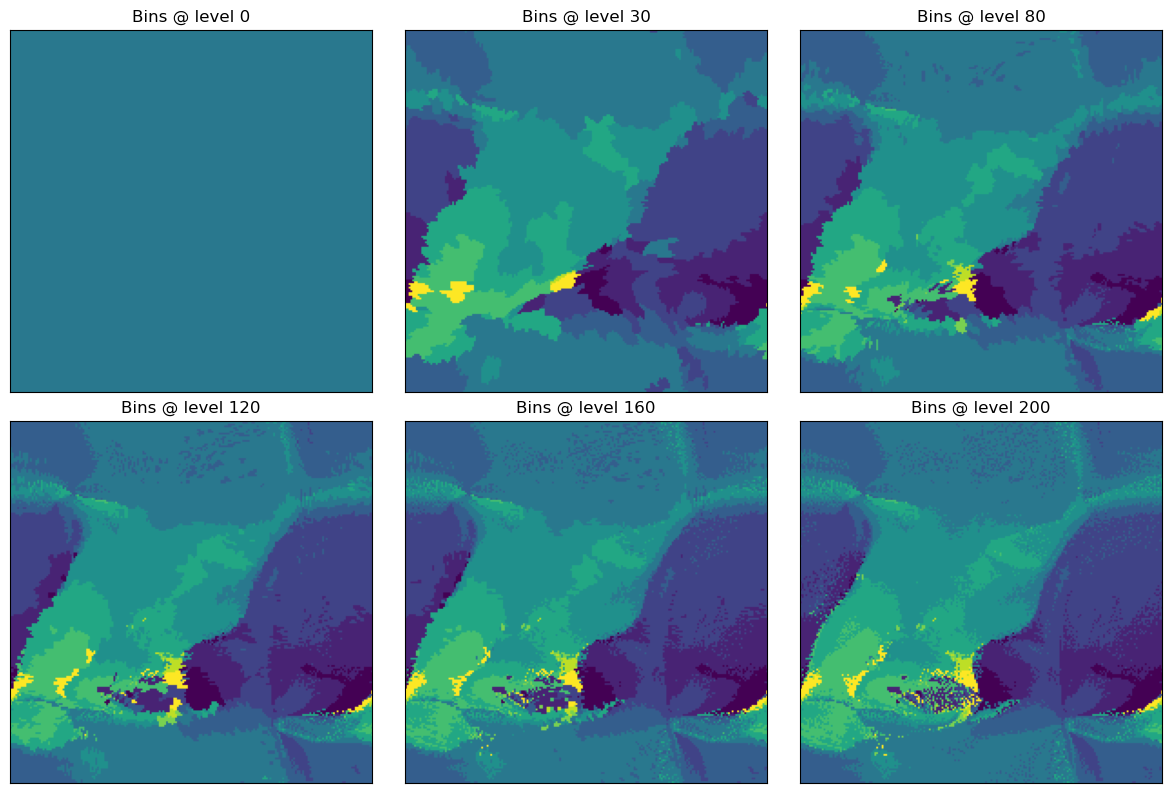

In [6]:
levels = [0, 30, 80, 120, 160, 200]  # adjust as you like

fig, axs = plt.subplots(2, 3, figsize=(12, 8))
axs = axs.ravel()

for ax, lvl in zip(axs, levels):
    grid = som.bins_grid_at_level(lvl, reducer="mode")
    ax.imshow(grid, vmin=0, vmax=K-1)
    ax.set_title(f"Bins @ level {lvl}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()


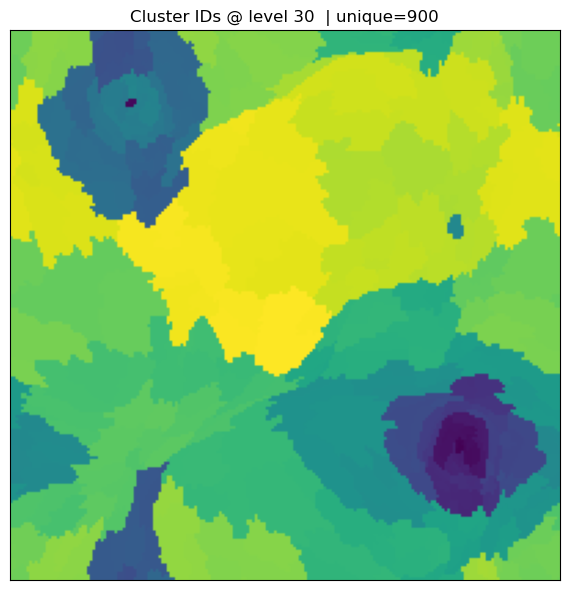

In [8]:
lvl = 30
cgrid = som.cluster_ids_at_level(lvl)
plt.figure(figsize=(6,6))
plt.imshow(cgrid)
plt.title(f"Cluster IDs @ level {lvl}  | unique={len(np.unique(cgrid))}")
plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()


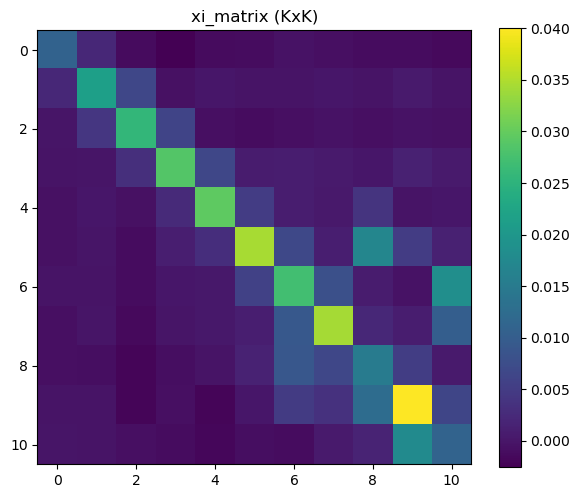

diag mean: 0.025319897364873865 off mean: 0.0015448037989280105
trace: 0.2785188710136125 energy: 0.023775093565945846


In [10]:
xi = som.xi_matrix()
plt.figure(figsize=(6,5))
plt.imshow(xi)
plt.title("xi_matrix (KxK)")
plt.colorbar()
plt.tight_layout()
plt.show()

diag = np.diag(xi)
off = xi[~np.eye(K, dtype=bool)]
print("diag mean:", diag.mean(), "off mean:", off.mean())
print("trace:", som.trace_xi(), "energy:", som.energy_E())


noop fraction: 0.0


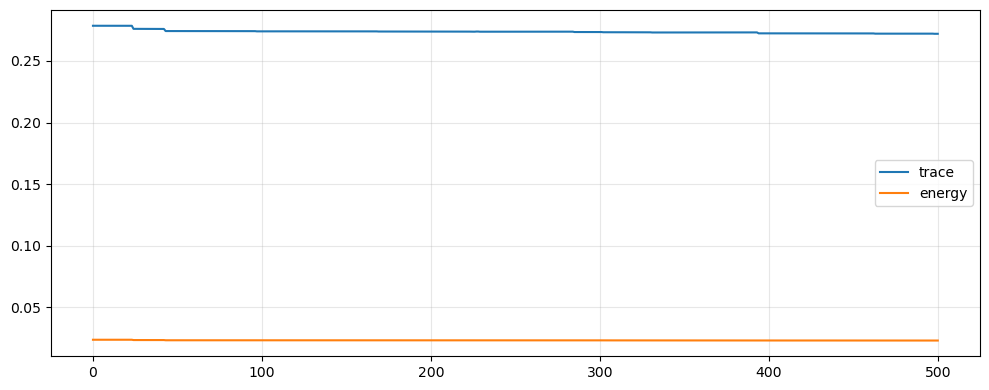

In [ ]:
rng = np.random.default_rng(0)
som.reset_to_initial()
eligible_nodes = np.flatnonzero(som.node_gal_counts > 0)
T = 1000

trace = np.zeros(T+1)
energy = np.zeros(T+1)
noop = 0

trace[0] = som.trace_xi()
energy[0] = som.energy_E()

for t in range(1, T+1):
    node = int(rng.choice(eligible_nodes))
    out = som.step_sa(node)
    noop += int(out["is_noop"])
    trace[t] = som.trace_xi()
    energy[t] = som.energy_E()

print("noop fraction:", noop / T)

plt.figure(figsize=(10,4))
plt.plot(trace, label="trace")
plt.plot(energy, label="energy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


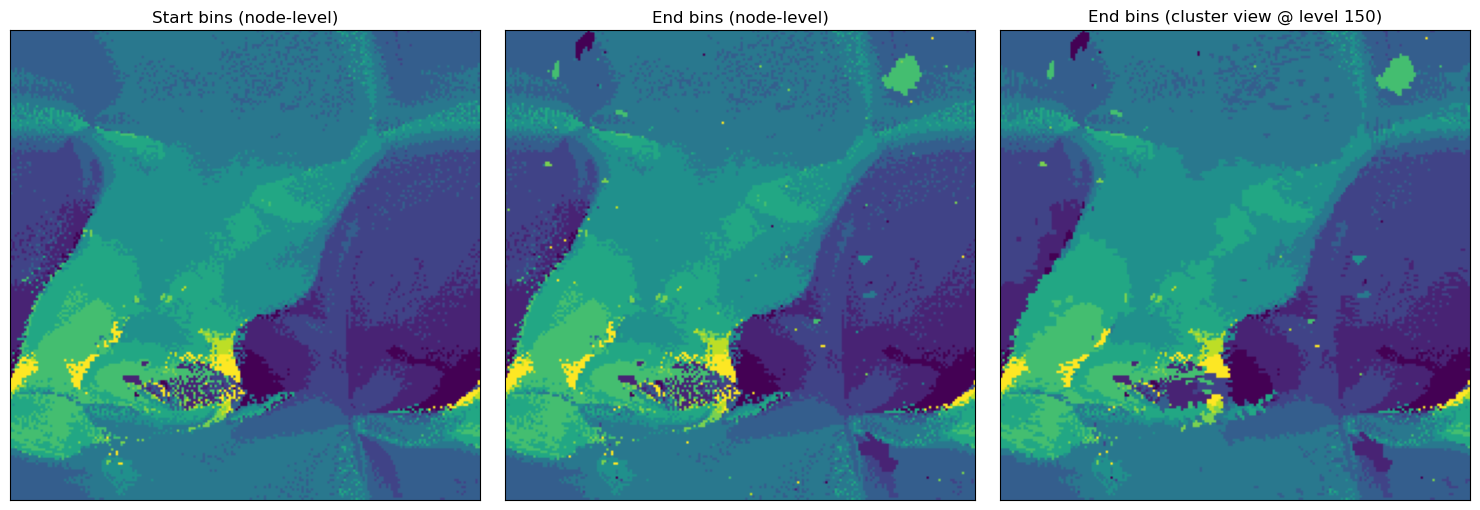

start trace/energy: 0.27200379610851355 0.023130695167883606


In [75]:
lvl = 150

start_bins = initial_node_bins.reshape(H,W)
end_bins   = som.bins_grid()

fig, axs = plt.subplots(1, 3, figsize=(15,5))
axs[0].imshow(start_bins, vmin=0, vmax=K-1)
axs[0].set_title("Start bins (node-level)")
axs[1].imshow(end_bins, vmin=0, vmax=K-1)
axs[1].set_title("End bins (node-level)")
axs[2].imshow(som.bins_grid_at_level(lvl), vmin=0, vmax=K-1)
axs[2].set_title(f"End bins (cluster view @ level {lvl})")

for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

print("start trace/energy:", float(np.trace(som.xi_matrix())), som.energy_E())


ACCEPT t=     2 node=25478 6->9  ΔE=8.051e-05
ACCEPT t=     3 node=20445 6->10  ΔE=1.460e-06
ACCEPT t=     6 node= 1638 3->10  ΔE=9.608e-07
ACCEPT t=     9 node= 7010 6->10  ΔE=3.312e-07
ACCEPT t=    10 node=32530 3->10  ΔE=8.605e-07
ACCEPT t=    13 node=20145 2->10  ΔE=8.347e-08
ACCEPT t=    17 node=25290 6->9  ΔE=7.176e-07
ACCEPT t=    18 node=21744 2->1  ΔE=6.015e-07
ACCEPT t=    22 node=32634 4->8  ΔE=1.900e-05
ACCEPT t=    24 node=  109 4->0  ΔE=2.856e-07

--- Summary ---
N_TRIES: 50000
Elapsed: 19.818s  |  2523.0 proposals/s
Accepted: 13146  | Rejected: 36854  | No-op proposals: 36854
Acceptance rate (overall): 0.2629
Tries to first ΔE>0: 2
Energy: start=2.377509e-02  end=3.508344e-02  Δ=1.130835e-02


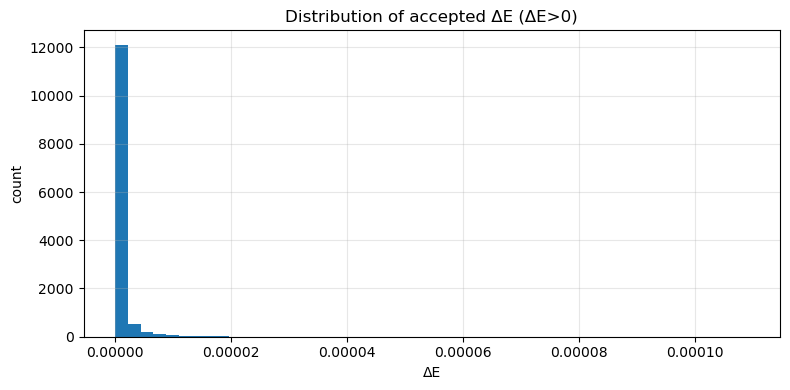

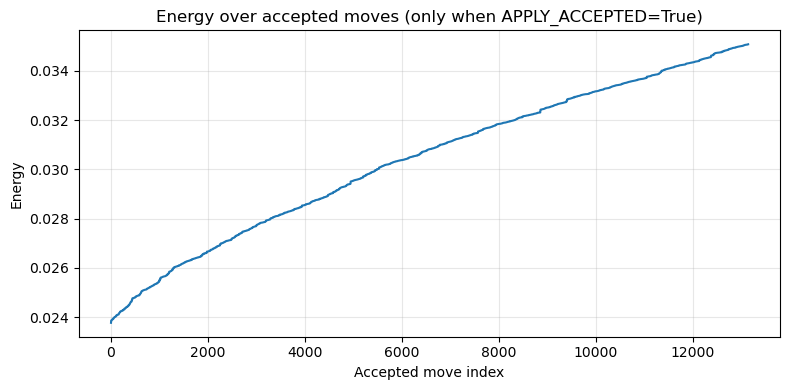

In [80]:
som.reset_to_initial()

# Cell — random node proposals, accept only if ΔE > 0, measure time-to-positive and acceptance stats

import time
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

# ---- config ----
N_TRIES = 50_000          # how many random node proposals to test
APPLY_ACCEPTED = True     # True: actually apply accepted moves to the SOM (state evolves)
                           # False: test proposals on the current state without updating
PRINT_FIRST_K = 10        # print first K accepted moves with their ΔE
USE_ELIGIBLE = True       # sample only nodes with >0 photo galaxies

# optional: ignore micro changes (noise)
MIN_POS_DELTA_E = 0.0     # set e.g. 1e-10 if you want a strict threshold

eligible_nodes = np.flatnonzero(som.node_gal_counts > 0) if USE_ELIGIBLE else np.arange(som.N, dtype=np.int64)

def propose_best_energy_move_for_node(som, node: int):
    """
    For a given node, evaluate all bins, return the best bin by ENERGY improvement (ΔE),
    along with ΔE. Does not mutate state.
    """
    oldb = int(som.current_bins[node])
    E0 = som.energy_E()

    bestb = oldb
    best_dE = 0.0

    for newb in range(som.K):
        if newb == oldb:
            continue
        if not som.valid_bin_for_node(node, newb):
            continue

        som._rank1_move(node, oldb, newb)
        E1 = som.energy_E()
        dE = float(E1 - E0)
        som._rank1_move(node, newb, oldb)

        if dE > best_dE:
            best_dE = dE
            bestb = int(newb)

    return bestb, best_dE

t0 = time.perf_counter()

# stats
tries_to_first_positive = None
accepted = 0
rejected = 0
noops = 0
accepted_steps = []
accepted_dEs = []

E_trace = [som.energy_E()]
E0_global = E_trace[0]

printed = 0

for t in range(1, N_TRIES + 1):
    node = int(rng.choice(eligible_nodes))

    bestb, dE = propose_best_energy_move_for_node(som, node)
    oldb = int(som.current_bins[node])

    if bestb == oldb:
        noops += 1
        rejected += 1
        continue

    if dE > MIN_POS_DELTA_E:
        # accept
        accepted += 1
        if tries_to_first_positive is None:
            tries_to_first_positive = t

        if APPLY_ACCEPTED:
            som._rank1_move(node, oldb, bestb)
            E_trace.append(som.energy_E())

        accepted_steps.append(t)
        accepted_dEs.append(dE)

        if printed < PRINT_FIRST_K:
            print(f"ACCEPT t={t:6d} node={node:5d} {oldb}->{bestb}  ΔE={dE:.3e}")
            printed += 1
    else:
        rejected += 1

t1 = time.perf_counter()
dt = t1 - t0

print("\n--- Summary ---")
print(f"N_TRIES: {N_TRIES}")
print(f"Elapsed: {dt:.3f}s  |  {N_TRIES/dt:.1f} proposals/s")
print(f"Accepted: {accepted}  | Rejected: {rejected}  | No-op proposals: {noops}")
print(f"Acceptance rate (overall): {accepted / max(1, N_TRIES):.4f}")
print(f"Tries to first ΔE>0: {tries_to_first_positive}")

if APPLY_ACCEPTED and len(E_trace) > 1:
    print(f"Energy: start={E0_global:.6e}  end={E_trace[-1]:.6e}  Δ={E_trace[-1]-E0_global:.6e}")

# ---- plots ----
if len(accepted_dEs) > 0:
    plt.figure(figsize=(8,4))
    plt.hist(accepted_dEs, bins=50)
    plt.title("Distribution of accepted ΔE (ΔE>0)")
    plt.xlabel("ΔE")
    plt.ylabel("count")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

if APPLY_ACCEPTED and len(E_trace) > 1:
    plt.figure(figsize=(8,4))
    plt.plot(E_trace)
    plt.title("Energy over accepted moves (only when APPLY_ACCEPTED=True)")
    plt.xlabel("Accepted move index")
    plt.ylabel("Energy")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


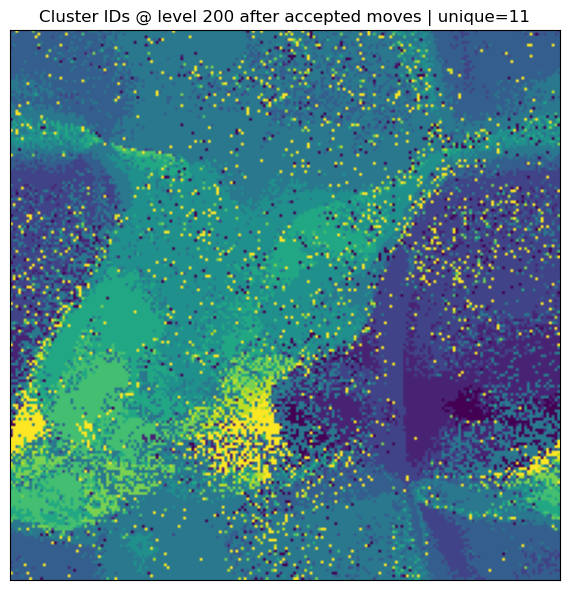

In [82]:
# Print the SOM state after the accepted moves
lvl = 200
grid = som.bins_grid_at_level(lvl, reducer="mode")
plt.figure(figsize=(6,6))
plt.imshow(grid, vmin=0, vmax=K-1)
plt.title(f"Cluster IDs @ level {lvl} after accepted moves | unique={len(np.unique(grid))}")
plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()

LEVEL=100 | clusters with >=1 eligible node: 9999
group sizes: min=1 median=2.0 max=61 mean=4.00
ACCEPT t=     9 level=100 cluster= 1752 size=   2  4->8  ΔE=3.644e-05
ACCEPT t=    17 level=100 cluster= 6322 size=  10  6->8  ΔE=3.351e-05
ACCEPT t=    32 level=100 cluster= 1756 size=   1  4->8  ΔE=3.394e-05
ACCEPT t=    48 level=100 cluster= 6471 size=   2  6->9  ΔE=8.691e-05
ACCEPT t=    58 level=100 cluster= 6854 size=   4  6->8  ΔE=1.103e-04
ACCEPT t=    86 level=100 cluster= 5942 size=  14  0->10  ΔE=1.446e-05
ACCEPT t=   157 level=100 cluster= 6036 size=   5  6->8  ΔE=8.733e-05
ACCEPT t=   197 level=100 cluster= 3671 size=   5  7->8  ΔE=3.541e-05
ACCEPT t=   239 level=100 cluster= 6245 size=   4  6->9  ΔE=9.319e-05
ACCEPT t=   284 level=100 cluster= 5938 size=  19  1->10  ΔE=4.488e-05

--- Summary ---
LEVEL: 100
N_TRIES: 50000
Elapsed: 42.106s  |  1187.5 proposals/s
Accepted: 324  | Rejected: 49676  | No-op proposals: 36316
Acceptance rate: 0.0065
Tries to first ΔE>0: 9
Energy: star

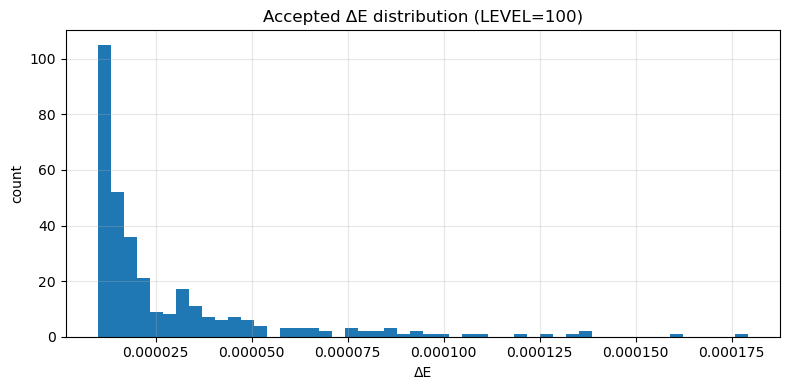

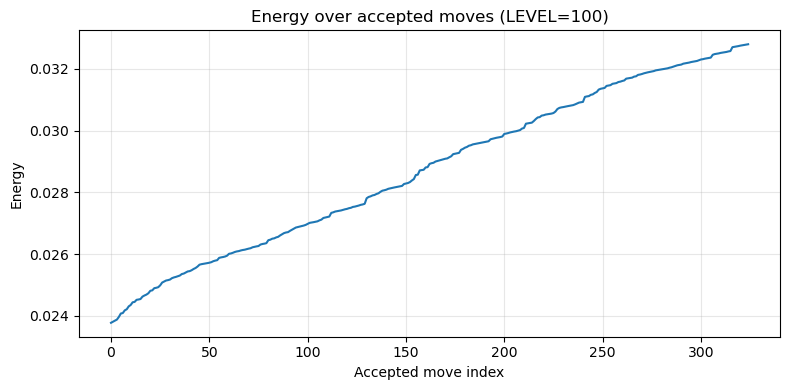

In [92]:
som.reset_to_initial()
# Cell — random node proposals with resolution-aware moves (SharpZ-style grouping)
# Accept only if ΔE>0 (or > MIN_POS_DELTA_E). Optionally apply accepted moves.
#
# Requires SOM backend to expose:
#   - som.energy() -> float
#   - som.current_bins (N,)
#   - som.valid_bin_for_node(node, b) -> bool
#   - som._rank1_move(node, oldb, newb)  (internal OK for notebook)
#   - som.H, som.W, som.N, som.K
#   - som.node_gal_counts (N,)
# And either:
#   A) som.weighted_clusters: np.ndarray shape (n_levels, N) giving cluster id per node for each level, OR
#   B) som.get_cluster_map(level) -> (N,) int cluster ids
#
# Resolution param "level": int index into weighted_clusters (0..n_levels-1).
# Higher level typically => finer (depends on how your file is defined; you can invert if needed).

import time
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

# ---- config ----
LEVEL = 100               # <-- set this (0..n_levels-1) to test different resolutions
N_TRIES = 50_000
APPLY_ACCEPTED = True
PRINT_FIRST_K = 10
USE_ELIGIBLE = True
MIN_POS_DELTA_E = 1e-5     # set e.g. 1e-10 to ignore micro-gains/noise

# If True: when proposing for a cluster, disallow bins that are invalid for ANY node in the cluster.
# If False: require validity only for the "representative" node (faster, but can violate per-node masks).
STRICT_VALIDITY = True


# ---- helpers ----
def get_cluster_ids_for_level(som, level: int) -> np.ndarray:
    if hasattr(som, "weighted_clusters") and som.weighted_clusters is not None:
        wc = np.asarray(som.weighted_clusters)
        if wc.ndim != 2:
            raise ValueError(f"weighted_clusters must be 2D (levels,N); got {wc.shape}")
        if not (0 <= level < wc.shape[0]):
            raise ValueError(f"LEVEL={level} out of range [0..{wc.shape[0]-1}]")
        if wc.shape[1] != som.N:
            raise ValueError(f"weighted_clusters second dim must be N={som.N}; got {wc.shape[1]}")
        return wc[level].astype(np.int64, copy=False)

    if hasattr(som, "get_cluster_map"):
        c = som.get_cluster_map(level)
        c = np.asarray(c, dtype=np.int64)
        if c.shape != (som.N,):
            raise ValueError(f"get_cluster_map(level) must return shape (N,), got {c.shape}")
        return c

    raise ValueError("Backend must provide som.weighted_clusters or som.get_cluster_map(level).")


def build_level_groups(cluster_ids: np.ndarray, eligible_nodes: np.ndarray):
    """
    Returns:
      - groups: dict cluster_id -> np.ndarray of node indices in that cluster (restricted to eligible_nodes)
      - cluster_list: np.ndarray of cluster_ids that have >=1 eligible node
    """
    # restrict to eligible
    cl = cluster_ids[eligible_nodes]
    # group via sorting
    order = np.argsort(cl, kind="mergesort")
    eligible_sorted = eligible_nodes[order]
    cl_sorted = cl[order]

    # find segment boundaries
    unique_c, starts = np.unique(cl_sorted, return_index=True)
    starts = np.append(starts, cl_sorted.size)

    groups = {}
    for i, cid in enumerate(unique_c):
        a = starts[i]
        b = starts[i+1]
        groups[int(cid)] = eligible_sorted[a:b]
    cluster_list = unique_c.astype(np.int64)
    return groups, cluster_list


def cluster_bin_counts(current_bins: np.ndarray, nodes: np.ndarray, K: int) -> np.ndarray:
    # counts of current bins within the cluster (useful if you want "majority bin" etc.)
    return np.bincount(current_bins[nodes], minlength=K).astype(np.int64)


def propose_best_energy_move_for_group(som, nodes: np.ndarray):
    """
    Group move: set ALL nodes in 'nodes' to the same target bin.
    Returns (best_bin, best_dE). Does not mutate the final state.
    """
    # pick representative old bin as "current majority" (SharpZ-like)
    # (You can change this to use a fixed representative node.)
    bins = som.current_bins[nodes]
    binc = np.bincount(bins, minlength=som.K)
    oldb = int(np.argmax(binc))

    E0 = som.energy_E()

    bestb = oldb
    best_dE = 0.0

    # precompute which nodes are currently != oldb (so we only move those on trial)
    mask_not_old = (bins != oldb)
    nodes_not_old = nodes[mask_not_old]

    # To "apply group to newb", we need to:
    #  1) move nodes_not_old that are currently != oldb -> oldb (to get a clean baseline)
    #  2) then move all nodes (now at oldb) -> newb
    #
    # But step 1 would mutate; instead we do direct baseline:
    # We'll just define baseline state as current, and for each candidate newb
    # we move each node individually from its current bin to newb, evaluate, then revert.
    #
    # This is O(|group| * K). For large groups it can be expensive.
    # If this is too slow, we can add a faster "batched rank-1" path in backend.

    # cache current bins for revert
    cur_bins = som.current_bins[nodes].copy()

    # candidate bins
    for newb in range(som.K):
        if newb == oldb:
            continue

        # validity: either strict across cluster or just rep node
        if STRICT_VALIDITY:
            ok = True
            for n in nodes:
                if not som.valid_bin_for_node(int(n), int(newb)):
                    ok = False
                    break
            if not ok:
                continue
        else:
            # representative validity: pick first node
            if not som.valid_bin_for_node(int(nodes[0]), int(newb)):
                continue

        # apply trial: move each node to newb if needed
        for i, n in enumerate(nodes):
            n = int(n)
            ob = int(cur_bins[i])
            if ob != newb:
                som._rank1_move(n, ob, newb)

        E1 = som.energy_E()
        dE = float(E1 - E0)

        # revert
        for i, n in enumerate(nodes):
            n = int(n)
            ob = int(cur_bins[i])
            nb = int(som.current_bins[n])
            if nb != ob:
                som._rank1_move(n, nb, ob)

        if dE > best_dE:
            best_dE = dE
            bestb = int(newb)

    # define action as: set all nodes to bestb (only if bestb != oldb)
    return bestb, best_dE


def apply_group_move(som, nodes: np.ndarray, newb: int):
    # move all nodes to newb (if not already)
    for n in nodes:
        n = int(n)
        ob = int(som.current_bins[n])
        if ob != newb:
            som._rank1_move(n, ob, int(newb))


# ---- setup groups for LEVEL ----
cluster_ids = get_cluster_ids_for_level(som, LEVEL)

eligible_nodes = np.flatnonzero(som.node_gal_counts > 0) if USE_ELIGIBLE else np.arange(som.N, dtype=np.int64)
groups, cluster_list = build_level_groups(cluster_ids, eligible_nodes)

print(f"LEVEL={LEVEL} | clusters with >=1 eligible node: {len(cluster_list)}")
# quick sanity: show typical group sizes
sizes = np.array([len(groups[int(cid)]) for cid in cluster_list], dtype=np.int64)
print(f"group sizes: min={sizes.min()} median={np.median(sizes)} max={sizes.max()} mean={sizes.mean():.2f}")

# ---- run proposals ----
t0 = time.perf_counter()

tries_to_first_positive = None
accepted = rejected = noops = 0
accepted_steps, accepted_dEs = [], []

E_trace = [som.energy_E()]
E0_global = E_trace[0]

printed = 0

for t in range(1, N_TRIES + 1):
    cid = int(rng.choice(cluster_list))
    nodes = groups[cid]

    # propose group move
    bestb, dE = propose_best_energy_move_for_group(som, nodes)

    # define "noop" as: bestb equals current majority bin in the group
    bins = som.current_bins[nodes]
    binc = np.bincount(bins, minlength=som.K)
    oldb = int(np.argmax(binc))
    if bestb == oldb:
        noops += 1
        rejected += 1
        continue

    if dE > MIN_POS_DELTA_E:
        accepted += 1
        if tries_to_first_positive is None:
            tries_to_first_positive = t

        if APPLY_ACCEPTED:
            apply_group_move(som, nodes, bestb)
            E_trace.append(som.energy_E())

        accepted_steps.append(t)
        accepted_dEs.append(dE)

        if printed < PRINT_FIRST_K:
            print(f"ACCEPT t={t:6d} level={LEVEL:3d} cluster={cid:5d} size={len(nodes):4d}  {oldb}->{bestb}  ΔE={dE:.3e}")
            printed += 1
    else:
        rejected += 1

t1 = time.perf_counter()
dt = t1 - t0

print("\n--- Summary ---")
print(f"LEVEL: {LEVEL}")
print(f"N_TRIES: {N_TRIES}")
print(f"Elapsed: {dt:.3f}s  |  {N_TRIES/dt:.1f} proposals/s")
print(f"Accepted: {accepted}  | Rejected: {rejected}  | No-op proposals: {noops}")
print(f"Acceptance rate: {accepted / max(1, N_TRIES):.4f}")
print(f"Tries to first ΔE>0: {tries_to_first_positive}")

if APPLY_ACCEPTED and len(E_trace) > 1:
    print(f"Energy: start={E0_global:.6e}  end={E_trace[-1]:.6e}  Δ={E_trace[-1]-E0_global:.6e}")

# ---- plots ----
if len(accepted_dEs) > 0:
    plt.figure(figsize=(8,4))
    plt.hist(accepted_dEs, bins=50)
    plt.title(f"Accepted ΔE distribution (LEVEL={LEVEL})")
    plt.xlabel("ΔE")
    plt.ylabel("count")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

if APPLY_ACCEPTED and len(E_trace) > 1:
    plt.figure(figsize=(8,4))
    plt.plot(E_trace)
    plt.title(f"Energy over accepted moves (LEVEL={LEVEL})")
    plt.xlabel("Accepted move index")
    plt.ylabel("Energy")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


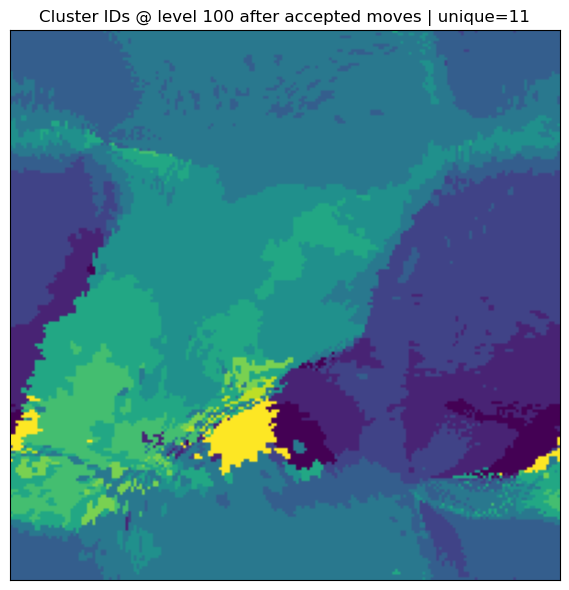

In [93]:
grid = som.bins_grid_at_level(LEVEL, reducer="mode")
plt.figure(figsize=(6,6))
plt.imshow(grid, vmin=0, vmax=K-1)
plt.title(f"Cluster IDs @ level {LEVEL} after accepted moves | unique={len(np.unique(grid))}")
plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()

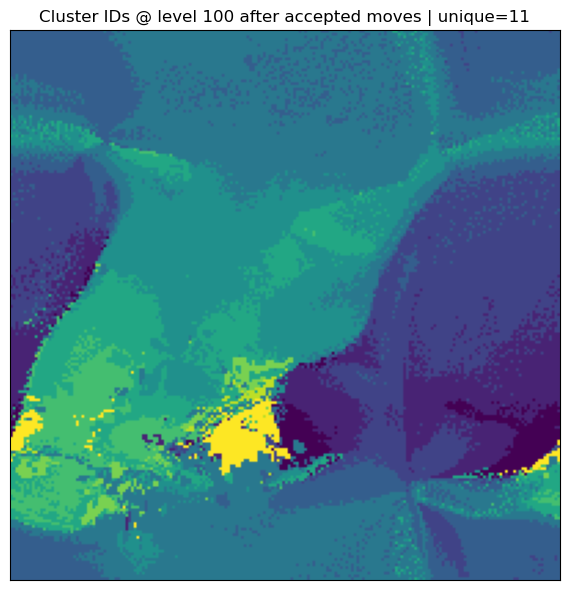

In [94]:
grid = som.bins_grid_at_level(200, reducer="mode")
plt.figure(figsize=(6,6))
plt.imshow(grid, vmin=0, vmax=K-1)
plt.title(f"Cluster IDs @ level {LEVEL} after accepted moves | unique={len(np.unique(grid))}")
plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()

In [95]:
from som_rl.eval.ideal_som import get_perfect_bins, plot_bins_triptych

In [97]:
perfect = get_perfect_bins()

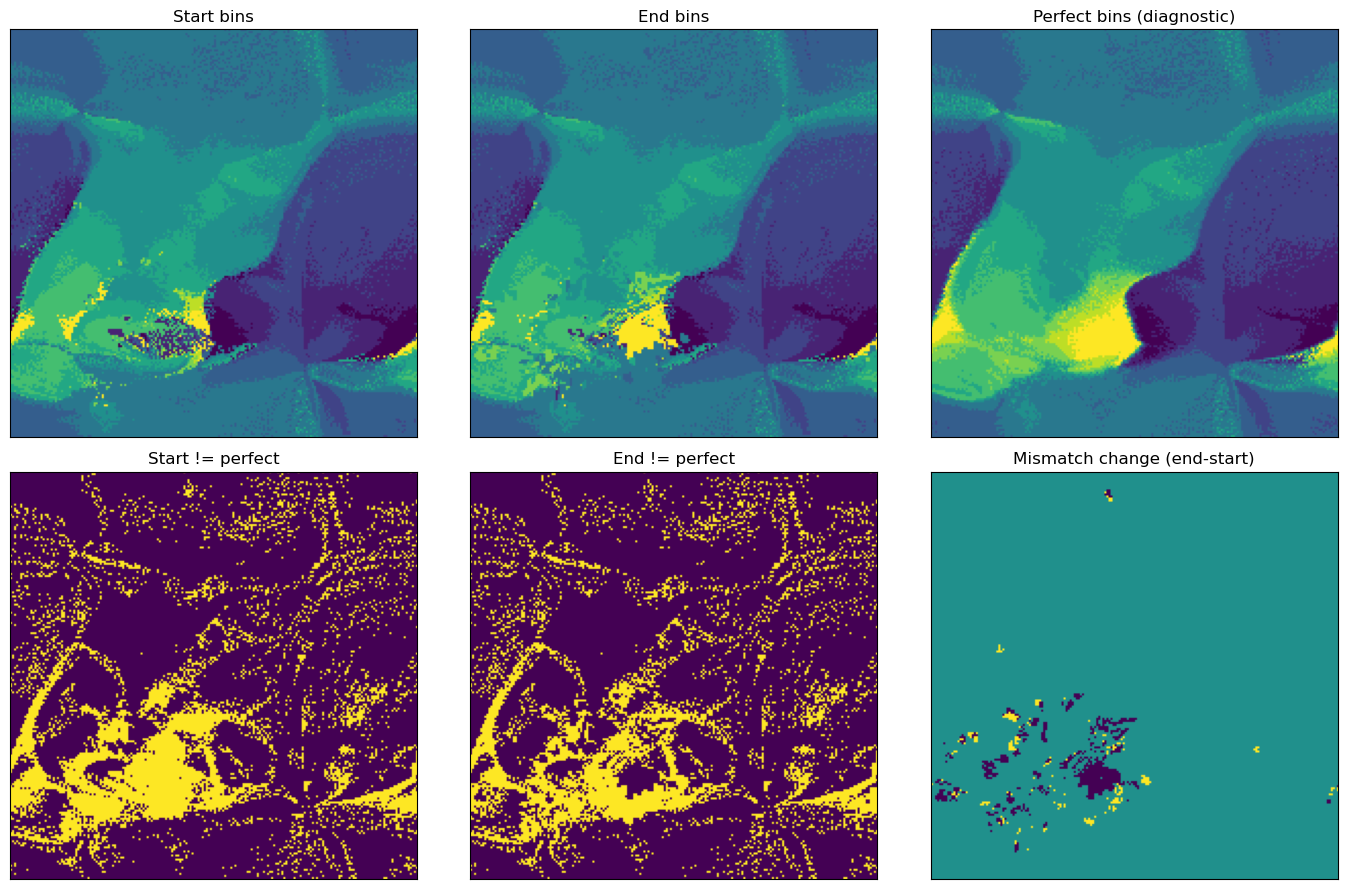

Match to perfect: start=0.795, end=0.808, Δ=+0.014


In [100]:
plot_bins_triptych(
    perfect_bins=perfect,
    end_bins=som.bins_grid(),
    start_bins=initial_node_bins.reshape(som.H, som.W)
)

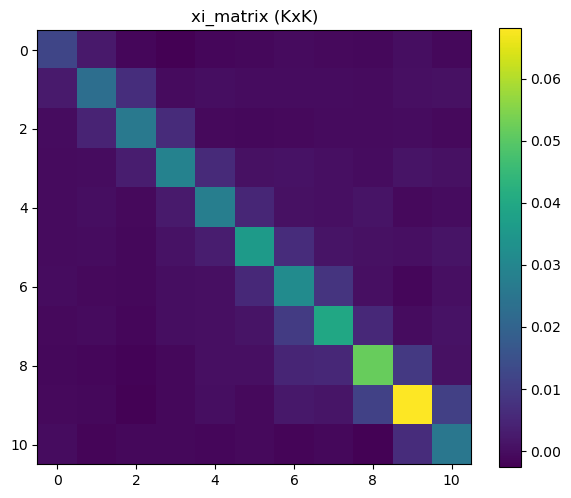

diag mean: 0.033692340830029595 off mean: 0.0008966896934025876
trace: 0.3706157491303256 energy: 0.03279565113662701


In [101]:
xi = som.xi_matrix()
plt.figure(figsize=(6,5))
plt.imshow(xi)
plt.title("xi_matrix (KxK)")
plt.colorbar()
plt.tight_layout()
plt.show()

diag = np.diag(xi)
off = xi[~np.eye(K, dtype=bool)]
print("diag mean:", diag.mean(), "off mean:", off.mean())
print("trace:", som.trace_xi(), "energy:", som.energy_E())